In [3]:

import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_files = glob.glob('/content/*.csv')

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError("CSV file not found in /content")

df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())


CSV files found: ['/content/World_Energy_By_Country_And_Region_1965_to_2023.csv']
Dataset shape: (111, 60)
Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [4]:

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find the country column
country_col = next(
    (c for c in df.columns
     if c.lower() in ['country', 'entity', 'country_name']),
    None
)

if country_col is None:
    raise ValueError("Country column not found. Check Cell 2 output.")

# Find year columns such as 1965, 1966, ..., 2023
year_cols = [
    c for c in df.columns
    if c.isdigit() and 1900 <= int(c) <= 2100
]

if not year_cols:
    raise ValueError("Year columns not found. Check Cell 2 output.")

# Select US if available; otherwise select a country with most yearly values
country_names = df[country_col].astype(str).str.strip()
us_mask = country_names.str.lower().isin(
    ['us', 'united states', 'united states of america']
)

if us_mask.any():
    selected_row = df.loc[us_mask].iloc[[0]].copy()
else:
    selected_row = (
        df.assign(_count=df[year_cols].notna().sum(axis=1))
          .sort_values('_count', ascending=False)
          .iloc[[0]]
          .drop(columns='_count')
    )

selected_country = selected_row[country_col].iloc[0]

# Convert wide format into yearly rows
data = selected_row.melt(
    id_vars=[country_col],
    value_vars=year_cols,
    var_name='Year',
    value_name='Energy_Consumption'
)

data['Year'] = pd.to_numeric(data['Year'], errors='coerce')
data['Energy_Consumption'] = pd.to_numeric(
    data['Energy_Consumption'], errors='coerce'
)

data = (
    data.dropna(subset=['Year'])
        .sort_values('Year')
        .reset_index(drop=True)
)

# Handle missing values
data['Energy_Consumption'] = (
    data['Energy_Consumption']
    .interpolate(limit_area='inside')
    .ffill()
    .bfill()
)

data = data.dropna(subset=['Energy_Consumption']).reset_index(drop=True)

print("Selected country:", selected_country)
print("Total yearly records:", len(data))
display(data.head())
display(data.tail())


Selected country: US
Total yearly records: 59


,Country,Year,Energy_Consumption
0,US,1965,51.98
1,US,1966,54.89
2,US,1967,56.80
3,US,1968,60.19
4,US,1969,63.30


,Country,Year,Energy_Consumption
54,US,2019,95.68
55,US,2020,88.64
56,US,2021,93.44
57,US,2022,95.42
58,US,2023,94.28


In [5]:

from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 5

values = data['Energy_Consumption'].to_numpy(
    dtype=np.float32
).reshape(-1, 1)

years = data['Year'].to_numpy()

# Chronological 80% training, 20% testing
split_index = int(len(values) * 0.8)

if len(values) < 10:
    raise ValueError("Not enough yearly records for training and testing.")

# Normalize using training data only
scaler = MinMaxScaler()
scaler.fit(values[:split_index])

scaled_values = scaler.transform(values)

X, y, target_indices = [], [], []

for i in range(LOOKBACK, len(scaled_values)):
    X.append(scaled_values[i-LOOKBACK:i])
    y.append(scaled_values[i, 0])
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

# Keep chronological order
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]
X_test = X[test_mask]
y_test = y[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (42, 5, 1)
y_train shape: (42,)
X_test shape: (12, 5, 1)
y_test shape: (12,)


In [6]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(50, activation='tanh'),
    Dense(25, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.3294 - val_loss: 0.5967
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.2337 - val_loss: 0.4347
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1669 - val_loss: 0.2953
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1057 - val_loss: 0.1685
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0535 - val_loss: 0.0665
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0168 - val_loss: 0.0098
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0047 - val_loss: 0.0075
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0124 - val_loss: 0.0202
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0163 - val_loss: 0.0124
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0114 - val_loss: 0.0037
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0079 - val_loss: 0.0036
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0072 - val_lo

In [7]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict test data
pred_scaled = model.predict(X_test)

# Convert to original energy consumption scale
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Selected country:", selected_country)
print("Model: LSTM")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

results = pd.DataFrame({
    'Year': years[target_indices[test_mask]],
    'Actual Consumption': actual,
    'Predicted Consumption': predicted
})

display(results)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
Selected country: US
Model: LSTM
MAE: 1.5507
RMSE: 2.3012


,Year,Actual Consumption,Predicted Consumption
0,2012,90.169998,94.208572
1,2013,92.620003,93.085304
2,2014,93.589996,92.603012
3,2015,92.690002,93.063889
4,2016,92.620003,92.963638
5,2017,92.970001,92.989143
6,2018,96.370003,93.446693
7,2019,95.680000,93.918404
8,2020,88.639999,94.266884
9,2021,93.440002,93.913010


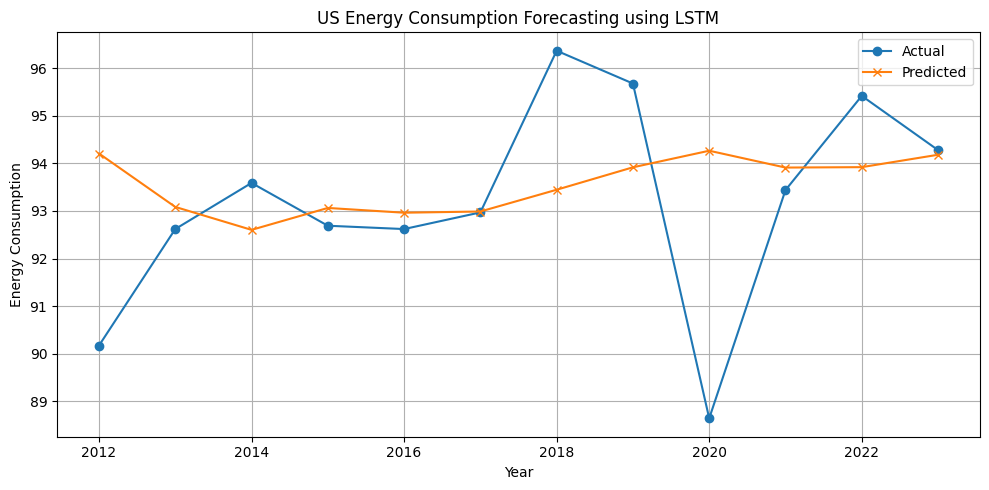

In [8]:

plt.figure(figsize=(10, 5))

plt.plot(
    results['Year'],
    results['Actual Consumption'],
    marker='o',
    label='Actual'
)

plt.plot(
    results['Year'],
    results['Predicted Consumption'],
    marker='x',
    label='Predicted'
)

plt.xlabel('Year')
plt.ylabel('Energy Consumption')
plt.title(f'{selected_country} Energy Consumption Forecasting using LSTM')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
